# Predicting Sales from Influencer Campaign Data


**Problem statement:**

Marketing teams often invest heavily in influencer campaigns — paying creators to promote products on social media platforms like Instagram. But understanding which factors actually drive product sales is critical to making better decisions about who to work with, how much to spend, and how to design content.

The goal is to build a predictive model that can estimate how many units of a product will be sold based on key influencer campaign attributes.


Complete end-to-end regression notebook for the messy influencer campaign case study.

**Covers:** loading, cleaning, EDA, feature engineering, baseline, model comparison, cross-validation, hyperparameter tuning, evaluation, feature importance, test prediction, reusable prediction pipeline, and exports.

## 1. Setup

Download `messy_train_data.csv` and `messy_test_data.csv`. The notebook searches `/content` first and asks for uploads if they are not found.


In [1]:
import os, re, glob, warnings, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Environment ready.")

Environment ready.


In [ ]:
# Install gdown
!pip -q install gdown

# Google Drive folder ID
FOLDER_ID = "1BCTayfVYwapGcGl3Mizik1E6-zPcQ_DT"

# Download the entire folder
!gdown --folder "https://drive.google.com/drive/folders/1BCTayfVYwapGcGl3Mizik1E6-zPcQ_DT" -O /content/data

Retrieving folder contents
Processing file 1m3ZO0DctdhpAsF2eyZcKxswkZ5VuurRa messy_test_data.csv
Processing file 17mNOMu0x-8Br9t3J2f0dcLrfq24eWv5Z messy_train_data.csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1m3ZO0DctdhpAsF2eyZcKxswkZ5VuurRa
To: /content/data/messy_test_data.csv
100% 162k/162k [00:00<00:00, 42.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=17mNOMu0x-8Br9t3J2f0dcLrfq24eWv5Z
To: /content/data/messy_train_data.csv
100% 709k/709k [00:00<00:00, 27.7MB/s]
Download completed


In [ ]:
for root, dirs, files in os.walk("/content/data"):
    for file in files:
        print(os.path.join(root, file))

/content/data/messy_test_data.csv
/content/data/messy_train_data.csv


In [ ]:
train_path = "/content/data/messy_train_data.csv"
test_path = "/content/data/messy_test_data.csv"

train_raw = pd.read_csv(train_path)
test_raw = pd.read_csv(test_path)

print("Train shape:", train_raw.shape)
print("Test shape :", test_raw.shape)

display(train_raw.head())
display(test_raw.head())

Train shape: (8000, 8)
Test shape : (2000, 7)


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,Sales (Units),ID,Timestamp,Notes
0,106572.0,2.573174871146172,2614.3781948587675,5.275680,6340,9254,2021-11-27,Pending
1,77583.0,0.9394984315675532,4975.962514379572,8.756268,5793,1561,2022-02-13,Review
2,92832.0,2.1761012652155296,4107.769534318886,6.454727,8104,1670,2023-09-25,Pending
3,53565.0,1.4783757541486553,4293.330464613049,4.312813,7293,6087,2023-02-15,Review
4,121079.0,3.3741976179329356,5343.549440897207,3.769047,14396,6669,2023-05-28,NaN


,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,ID,Timestamp,Notes
0,179136.0,2.5570425842061986,3975.099954173261,1.803620,6252,2021-10-08,Good
1,68888.0,3.451254744278324,5392.048613170361,2.993966,4684,2021-10-01,Good
2,89520.0,0.7342357926528821,5850.470394900652,4.525990,1731,2021-06-24,NaN
3,100048.0,1.5972073367018218,5792.432498712002,5.051500,4742,2021-11-22,NaN
4,132229.0,1.3874265375395036,5095.269891920688,3.580921,4521,2021-07-19,Review


## 2. Column Detection and Raw Data Audit

In [ ]:
def normalize_column_name(col):
    col = str(col).strip()
    col = re.sub(r"[%()]", "", col)
    col = re.sub(r"[^A-Za-z0-9]+", "_", col)
    col = re.sub(r"_+", "_", col)
    return col.strip("_")

train = train_raw.copy()
test = test_raw.copy()

train.columns = [normalize_column_name(c) for c in train.columns]
test.columns = [normalize_column_name(c) for c in test.columns]

def find_column(df, exact_names=(), contains=None):
    lookup = {c.lower(): c for c in df.columns}
    for name in exact_names:
        if name.lower() in lookup:
            return lookup[name.lower()]
    if contains:
        for c in df.columns:
            if contains.lower() in c.lower():
                return c
    return None

TARGET = find_column(train, ["Sales", "sales_units", "units_sold"], "sales")
FOLLOWERS_COL = find_column(train, ["Followers", "followers_count"], "follower")
ENGAGEMENT_COL = find_column(train, ["EngagementRate", "Engagement_Rate"], "engagement")
ADSPEND_COL = find_column(train, ["AdSpend", "Ad_Spend"], "spend")
CONTENT_COL = find_column(train, ["ContentQuality", "Content_Quality"], "content")
TIMESTAMP_COL = find_column(train, ["Timestamp", "CampaignTimestamp", "Date"], "timestamp")

print("TARGET          :", TARGET)
print("FOLLOWERS       :", FOLLOWERS_COL)
print("ENGAGEMENT RATE :", ENGAGEMENT_COL)
print("AD SPEND        :", ADSPEND_COL)
print("CONTENT QUALITY :", CONTENT_COL)
print("TIMESTAMP       :", TIMESTAMP_COL)

if TARGET is None:
    raise ValueError("Sales target column could not be detected.")


TARGET          : Sales_Units
FOLLOWERS       : Followers
ENGAGEMENT RATE : EngagementRate
AD SPEND        : AdSpend_GBP
CONTENT QUALITY : ContentQuality
TIMESTAMP       : Timestamp


In [ ]:
quality = pd.DataFrame({
    "dtype": train.dtypes.astype(str),
    "missing": train.isna().sum(),
    "missing_pct": train.isna().mean().mul(100).round(2),
    "unique": train.nunique()
}).sort_values("missing_pct", ascending=False)

display(quality)

for col in train.columns:
    print("\n" + "=" * 60)
    print(col)
    print(train[col].dropna().astype(str).head(10).tolist())

,dtype,missing,missing_pct,unique
Notes,object,2652,33.15,4
Followers,float64,160,2.00,7403
ContentQuality,float64,160,2.00,7840
EngagementRate,object,160,2.00,7800
AdSpend_GBP,object,159,1.99,7815
Sales_Units,int64,0,0.00,5582
ID,int64,0,0.00,8000
Timestamp,object,0,0.00,1000



Followers
['106572.0', '77583.0', '92832.0', '53565.0', '121079.0', '30578.0', '62648.0', '71757.0', '115007.0', '76227.0']

EngagementRate
['2.573174871146172', '0.9394984315675532', '2.1761012652155296', '1.4783757541486553', '3.3741976179329356', '2.960609116615305', '4.661459088961558', '3.3421014926558894', '3.0891652917157257', '2.7434519524908194']

AdSpend_GBP
['2614.3781948587675', '4975.962514379572', '4107.769534318886', '4293.330464613049', '5343.549440897207', '6640.860427448698', '3594.5211897372737', '4447.20233454365', '3940.505439955562', '7594.681081184365']

ContentQuality
['5.2756801191454885', '8.75626791367936', '6.454726997519417', '4.31281296087897', '3.769046633115465', '8.643337185416053', '2.951550238875863', '1.6655886303503693', '3.131948518566964', '3.1517547687668253']

Sales_Units
['6340', '5793', '8104', '7293', '14396', '8478', '7493', '6932', '9209', '11357']

ID
['9254', '1561', '1670', '6087', '6669', '5933', '8829', '7945', '3508', '2002']

Timest

## 3. Robust Cleaning

The parser handles values such as `£5000`, `5,000`, `3.2%`, `250K`, `1.5M`, `2B`, and parenthesized negatives.

Impossible business values are converted to missing so that the model's imputation pipeline can handle them without leaking validation/test information.


In [ ]:
def parse_numeric(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float, np.integer, np.floating)):
        return float(value)

    s = str(value).strip()
    if not s:
        return np.nan

    negative = s.startswith("(") and s.endswith(")")
    s = s.replace(",", "")
    is_percent = "%" in s

    suffix_match = re.search(r"([KkMmBb])$", s)
    multiplier = 1.0

    if suffix_match:
        multiplier = {
            "K": 1e3,
            "M": 1e6,
            "B": 1e9
        }[suffix_match.group(1).upper()]
        s = s[:-1]

    s = re.sub(r"[^0-9eE.+-]", "", s)

    if not s:
        return np.nan

    try:
        x = float(s) * multiplier
        if negative:
            x = -x
        if is_percent:
            x /= 100.0
        return x
    except Exception:
        return np.nan


def clean_core(df, include_target=False):
    df = df.copy()

    numeric_cols = [
        FOLLOWERS_COL,
        ENGAGEMENT_COL,
        ADSPEND_COL,
        CONTENT_COL
    ]

    if include_target:
        numeric_cols.append(TARGET)

    for col in numeric_cols:
        if col and col in df.columns:
            df[col] = df[col].apply(parse_numeric)

    # Standardize percentage-point engagement rates.
    if ENGAGEMENT_COL and ENGAGEMENT_COL in df.columns:
        med = df[ENGAGEMENT_COL].median()
        if pd.notna(med) and med > 1:
            df[ENGAGEMENT_COL] = df[ENGAGEMENT_COL] / 100.0

    # Business validation.
    if FOLLOWERS_COL in df.columns:
        df.loc[df[FOLLOWERS_COL] < 0, FOLLOWERS_COL] = np.nan

    if ADSPEND_COL in df.columns:
        df.loc[df[ADSPEND_COL] < 0, ADSPEND_COL] = np.nan

    if ENGAGEMENT_COL in df.columns:
        df.loc[
            (df[ENGAGEMENT_COL] < 0) | (df[ENGAGEMENT_COL] > 1),
            ENGAGEMENT_COL
        ] = np.nan

    if CONTENT_COL in df.columns:
        df.loc[
            (df[CONTENT_COL] < 1) | (df[CONTENT_COL] > 10),
            CONTENT_COL
        ] = np.nan

    if include_target and TARGET in df.columns:
        df.loc[df[TARGET] < 0, TARGET] = np.nan

    return df


train = clean_core(train, include_target=True)
test = clean_core(test, include_target=False)

print("Cleaning completed.")


Cleaning completed.


## 4. Exploratory Data Analysis

In [ ]:
display(train.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Followers,7840.0,NaN,NaN,NaN,1111104.467602,40130384.889415,20.0,78002.5,99120.5,119865.5,1629447388.0
EngagementRate,7837.0,NaN,NaN,NaN,0.027118,0.013588,0.000051,0.015589,0.027492,0.038823,0.049997
AdSpend_GBP,7838.0,NaN,NaN,NaN,193216.820368,11706360.763946,1000.0,3976.328415,5006.486783,6005.033554,932233948.827557
ContentQuality,7840.0,NaN,NaN,NaN,5.492899,2.608038,1.000151,3.227357,5.468786,7.780281,9.999749
Sales_Units,8000.0,NaN,NaN,NaN,10544.674375,2808.151485,590.0,8642.25,10500.0,12459.0,20263.0
ID,8000.0,NaN,NaN,NaN,5011.506875,2887.649416,1.0,2511.75,5013.5,7504.25,9999.0
Timestamp,8000,1000,2022-09-17,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Notes,5348,4,Pending,1367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


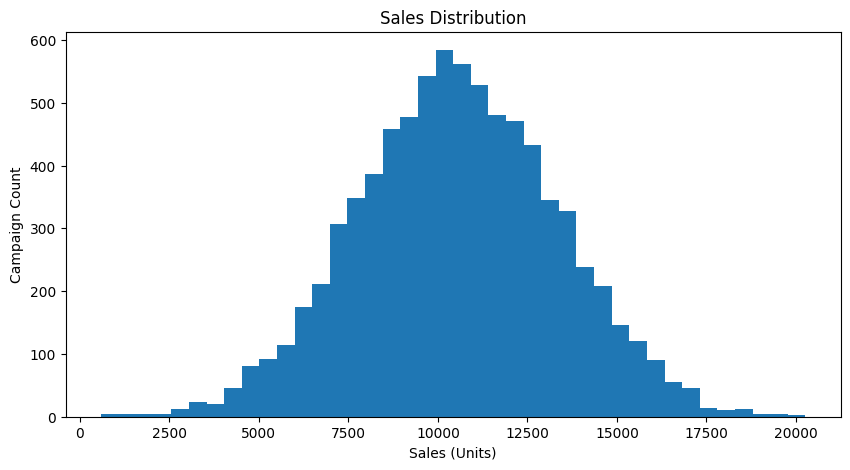

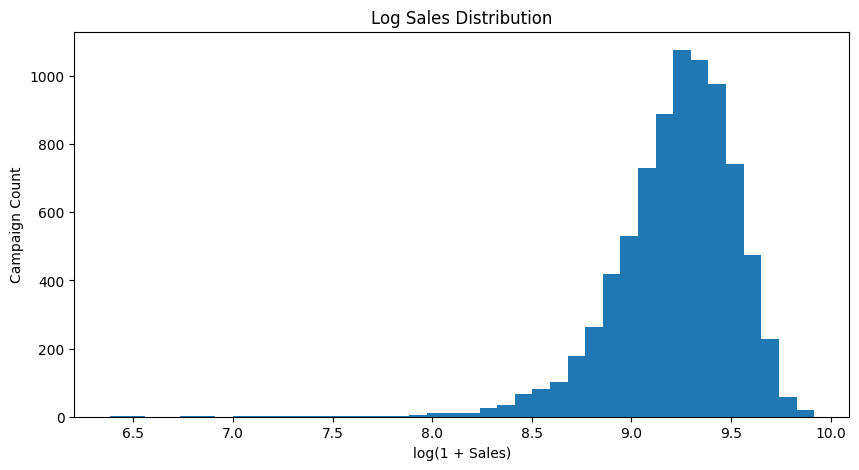

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(train[TARGET].dropna(), bins=40)
plt.xlabel("Sales (Units)")
plt.ylabel("Campaign Count")
plt.title("Sales Distribution")
plt.show()

positive_sales = train.loc[
    train[TARGET].notna() & (train[TARGET] >= 0),
    TARGET
]

plt.figure(figsize=(10, 5))
plt.hist(np.log1p(positive_sales), bins=40)
plt.xlabel("log(1 + Sales)")
plt.ylabel("Campaign Count")
plt.title("Log Sales Distribution")
plt.show()


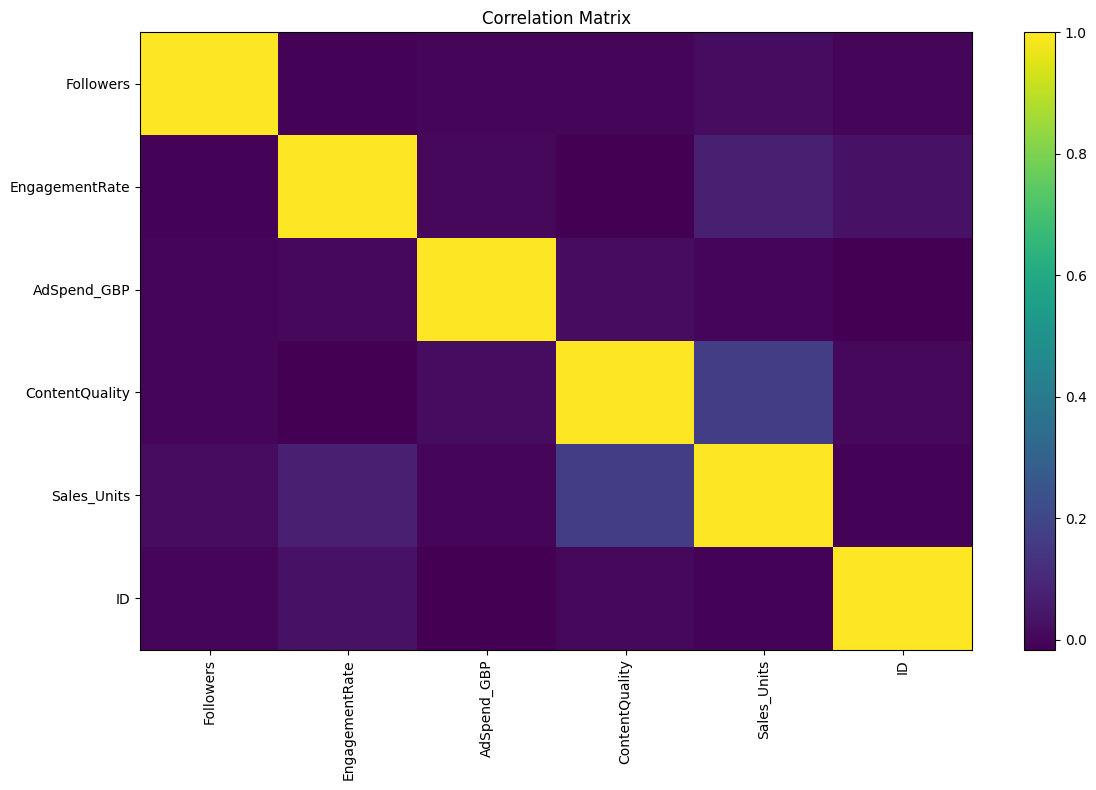

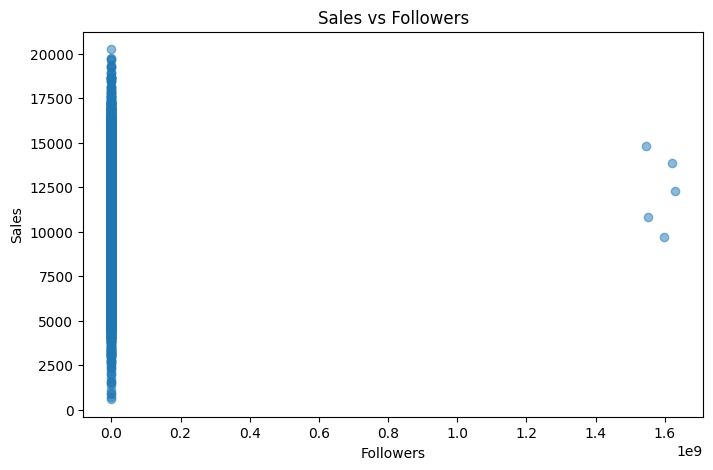

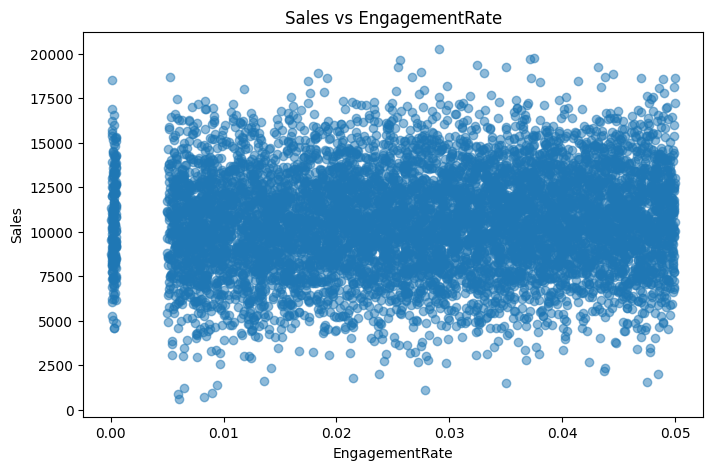

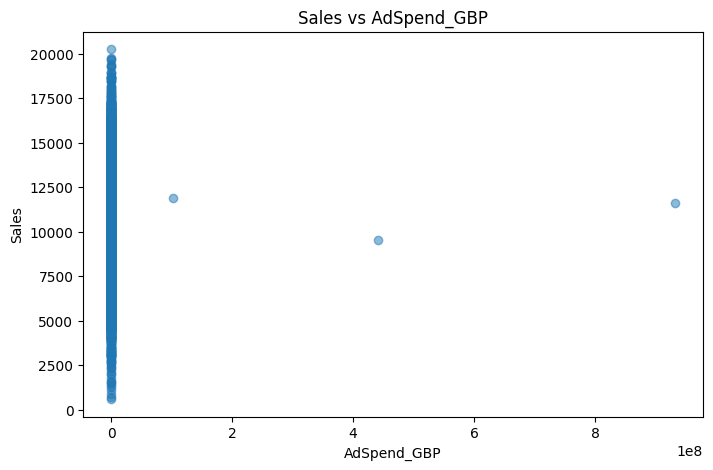

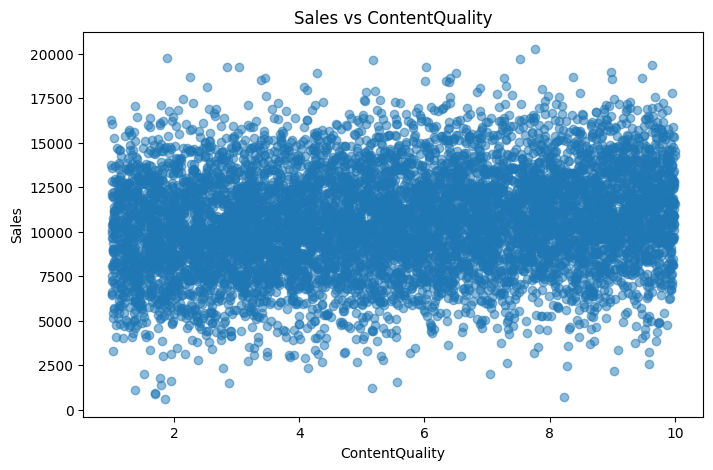

In [ ]:
numeric_data = train.select_dtypes(include=np.number)
corr = numeric_data.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
plt.imshow(corr, aspect="auto")
plt.colorbar()
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

for col in [FOLLOWERS_COL, ENGAGEMENT_COL, ADSPEND_COL, CONTENT_COL]:
    if col and col in train.columns:
        tmp = train[[col, TARGET]].dropna()

        plt.figure(figsize=(8, 5))
        plt.scatter(tmp[col], tmp[TARGET], alpha=0.5)
        plt.xlabel(col)
        plt.ylabel("Sales")
        plt.title(f"Sales vs {col}")
        plt.show()


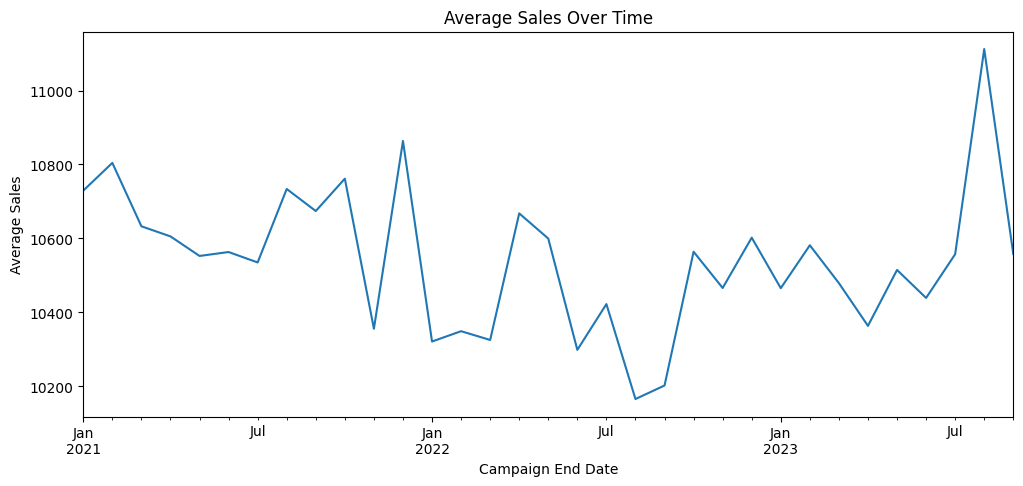

In [ ]:
if TIMESTAMP_COL and TIMESTAMP_COL in train.columns:
    dt = pd.to_datetime(train[TIMESTAMP_COL], errors="coerce")
    ts = pd.DataFrame({
        "date": dt,
        "sales": train[TARGET]
    }).dropna().sort_values("date")

    if len(ts):
        monthly = ts.set_index("date")["sales"].resample("ME").mean()

        plt.figure(figsize=(12, 5))
        monthly.plot()
        plt.xlabel("Campaign End Date")
        plt.ylabel("Average Sales")
        plt.title("Average Sales Over Time")
        plt.show()
    else:
        print("No usable timestamps found.")


## 5. Feature Engineering

In [ ]:
def add_features(df):
    df = df.copy()

    # Timestamp features
    if TIMESTAMP_COL and TIMESTAMP_COL in df.columns:
        dt = pd.to_datetime(df[TIMESTAMP_COL], errors="coerce")

        df["campaign_year"] = dt.dt.year
        df["campaign_month"] = dt.dt.month
        df["campaign_dayofweek"] = dt.dt.dayofweek
        df["campaign_quarter"] = dt.dt.quarter

        df["month_sin"] = np.sin(
            2 * np.pi * df["campaign_month"] / 12
        )
        df["month_cos"] = np.cos(
            2 * np.pi * df["campaign_month"] / 12
        )

    # Log transforms
    if FOLLOWERS_COL and FOLLOWERS_COL in df.columns:
        df["log_followers"] = np.log1p(
            df[FOLLOWERS_COL].clip(lower=0)
        )

    if ADSPEND_COL and ADSPEND_COL in df.columns:
        df["log_ad_spend"] = np.log1p(
            df[ADSPEND_COL].clip(lower=0)
        )

    # Reach × engagement
    if FOLLOWERS_COL in df.columns and ENGAGEMENT_COL in df.columns:
        df["estimated_engaged_audience"] = (
            df[FOLLOWERS_COL] * df[ENGAGEMENT_COL]
        )
        df["log_engaged_audience"] = np.log1p(
            df["estimated_engaged_audience"].clip(lower=0)
        )

    # Interactions
    if ENGAGEMENT_COL in df.columns and ADSPEND_COL in df.columns:
        df["engagement_x_adspend"] = (
            df[ENGAGEMENT_COL] * df[ADSPEND_COL]
        )

    if FOLLOWERS_COL in df.columns and ADSPEND_COL in df.columns:
        df["spend_per_follower"] = (
            df[ADSPEND_COL] /
            df[FOLLOWERS_COL].replace(0, np.nan)
        )
        df["followers_per_spend"] = (
            df[FOLLOWERS_COL] /
            df[ADSPEND_COL].replace(0, np.nan)
        )

    if CONTENT_COL in df.columns and ENGAGEMENT_COL in df.columns:
        df["quality_x_engagement"] = (
            df[CONTENT_COL] * df[ENGAGEMENT_COL]
        )

    if CONTENT_COL in df.columns and ADSPEND_COL in df.columns:
        df["quality_x_adspend"] = (
            df[CONTENT_COL] * df[ADSPEND_COL]
        )

    return df


train_fe = add_features(train)
test_fe = add_features(test)

valid_target = train_fe[TARGET].notna()

X = train_fe.loc[
    valid_target
].drop(columns=[TARGET], errors="ignore").copy()

y = train_fe.loc[
    valid_target, TARGET
].copy()

X_test = test_fe.copy()

DROP_COLUMNS = []

for c in X.columns:
    cl = c.lower()

    if cl in {"id", "campaign_id", "record_id"}:
        DROP_COLUMNS.append(c)

    if "note" in cl:
        DROP_COLUMNS.append(c)

    if c == TIMESTAMP_COL:
        DROP_COLUMNS.append(c)

DROP_COLUMNS = list(dict.fromkeys(DROP_COLUMNS))

X = X.drop(columns=DROP_COLUMNS, errors="ignore")
X_test = X_test.drop(columns=DROP_COLUMNS, errors="ignore")

print("Dropped:", DROP_COLUMNS)
print("Training features:", X.shape[1])
print("Features:", X.columns.tolist())


Dropped: ['ID', 'Timestamp', 'Notes']
Training features: 19
Features: ['Followers', 'EngagementRate', 'AdSpend_GBP', 'ContentQuality', 'campaign_year', 'campaign_month', 'campaign_dayofweek', 'campaign_quarter', 'month_sin', 'month_cos', 'log_followers', 'log_ad_spend', 'estimated_engaged_audience', 'log_engaged_audience', 'engagement_x_adspend', 'spend_per_follower', 'followers_per_spend', 'quality_x_engagement', 'quality_x_adspend']


## 6. Train/Validation Split and Preprocessing

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Train:", X_train.shape)
print("Validation:", X_valid.shape)


Numeric features: ['Followers', 'EngagementRate', 'AdSpend_GBP', 'ContentQuality', 'campaign_year', 'campaign_month', 'campaign_dayofweek', 'campaign_quarter', 'month_sin', 'month_cos', 'log_followers', 'log_ad_spend', 'estimated_engaged_audience', 'log_engaged_audience', 'engagement_x_adspend', 'spend_per_follower', 'followers_per_spend', 'quality_x_engagement', 'quality_x_adspend']
Categorical features: []
Train: (6400, 19)
Validation: (1600, 19)


## 7. Baseline

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
baseline_pred = np.repeat(y_train.mean(), len(y_valid))

baseline_rmse = np.sqrt(
    mean_squared_error(y_valid, baseline_pred)
)
baseline_mae = mean_absolute_error(y_valid, baseline_pred)

baseline_r2 = r2_score(y_valid, baseline_pred)

print(f"Baseline RMSE: {baseline_rmse:.4f}")
print(f"Baseline R²:   {baseline_r2:.4f}")
print(f"Baseline MAE : {baseline_mae:.4f}")

Baseline RMSE: 2820.1778
Baseline R²:   -0.0009
Baseline MAE : 2249.7002


## 8. Compare Regression Models

In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge": Ridge(alpha=10.0),

    "Random Forest": RandomForestRegressor(
        n_estimators=500,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesRegressor(
        n_estimators=500,
        min_samples_leaf=2,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        min_samples_leaf=5,
        loss="huber",
        random_state=42
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.05,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=42
    )
}

In [ ]:
def make_pipeline(model):
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

In [ ]:
model_results = []
fitted_models = {}

for name, estimator in models.items():

    print(f"Training: {name}")
    pipe = make_pipeline(estimator)
    pipe.fit(X_train, y_train)
    pred = np.maximum( pipe.predict(X_valid), 0 )

    # IMPORTANT:
    # Do NOT use squared=False.
    # Calculate RMSE manually.
    rmse = np.sqrt(mean_squared_error(y_valid, pred))
    mae = mean_absolute_error(y_valid,pred)
    r2 = r2_score(y_valid,pred)

    model_results.append({
        "Model": name,
        "Validation RMSE": rmse,
        "Validation MAE": mae,
        "Validation R2": r2
    })

    fitted_models[name] = pipe

comparison = pd.DataFrame(model_results).sort_values("Validation RMSE")


display(comparison)


Training: Linear Regression
Training: Ridge
Training: Random Forest
Training: Extra Trees
Training: Gradient Boosting
Training: HistGradientBoosting


,Model,Validation RMSE,Validation MAE,Validation R2
4,Gradient Boosting,2081.579835,1667.759456,0.454688
3,Extra Trees,2113.720631,1686.386728,0.437718
2,Random Forest,2115.015564,1687.796707,0.437029
5,HistGradientBoosting,2120.150841,1703.483059,0.434292
1,Ridge,110717.729231,4734.741863,-1541.740913
0,Linear Regression,124845.776989,5087.826066,-1960.581559


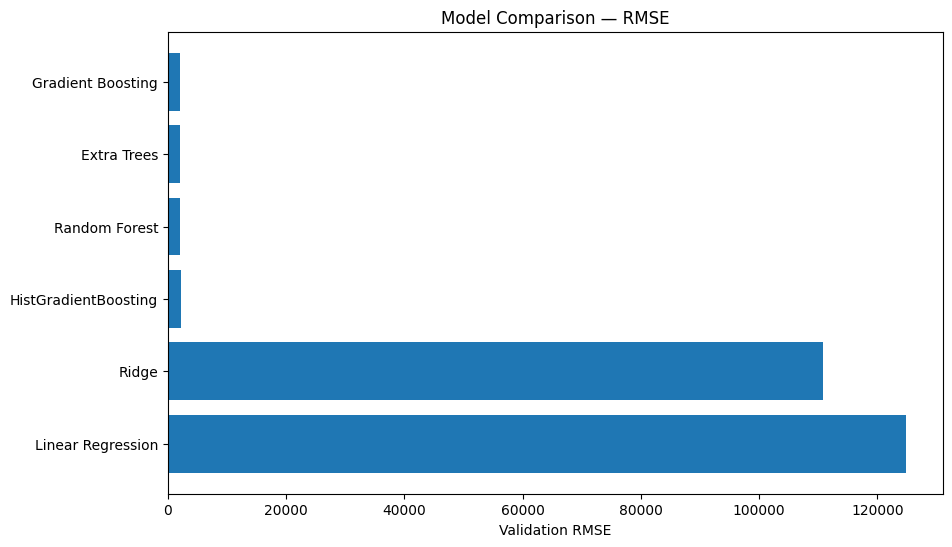

In [ ]:
plot_df = comparison.sort_values("Validation RMSE")
plt.figure(figsize=(10, 6))
plt.barh(
    plot_df["Model"],
    plot_df["Validation RMSE"]
)
plt.xlabel("Validation RMSE")
plt.title("Model Comparison — RMSE")
plt.gca().invert_yaxis()
plt.show()

## 9. Five-Fold Cross Validation

In [ ]:
cv = KFold(n_splits=5, shuffle=True,random_state=42)
cv_rows = []
for name, estimator in models.items():
    pipe = make_pipeline(estimator)
    scores = cross_validate(
        pipe,
        X,
        y,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=-1
    )
    cv_rows.append({
        "Model": name,
        "Mean CV RMSE": -scores["test_rmse"].mean(),
        "Std CV RMSE": scores["test_rmse"].std(),
        "Mean CV MAE": -scores["test_mae"].mean(),
        "Mean CV R2": scores["test_r2"].mean(),
        "Std CV R2": scores["test_r2"].std()
    })
cv_results = pd.DataFrame(cv_rows).sort_values( "Mean CV RMSE")
display(cv_results)

,Model,Mean CV RMSE,Std CV RMSE,Mean CV MAE,Mean CV R2,Std CV R2
4,Gradient Boosting,2032.295276,43.040227,1619.754212,0.475694,0.021557
2,Random Forest,2058.225575,47.362572,1641.291607,0.462304,0.021325
3,Extra Trees,2071.485284,45.402613,1652.072793,0.455313,0.021921
5,HistGradientBoosting,2079.063014,42.943354,1661.925208,0.451360,0.020335
1,Ridge,98519.767151,146593.560761,4805.701103,-3935.655565,7178.199594
0,Linear Regression,116914.553793,173164.337689,5329.943035,-5508.958953,9980.228981


## 10. Hyperparameter Tuning — Random Forest

In [ ]:
rf_pipe = make_pipeline(RandomForestRegressor(random_state=42,n_jobs=-1))
rf_params = {
    "model__n_estimators": [300, 500, 800],
    "model__max_depth": [None, 8, 12, 20, 30],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", "log2", 0.7, 1.0]
}
rf_search = RandomizedSearchCV(
    rf_pipe,
    rf_params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
rf_search.fit(X, y)

print("Best RF parameters:")
print(rf_search.best_params_)
print("Best RF CV RMSE:", -rf_search.best_score_)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best RF parameters:
{'model__n_estimators': 800, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_features': 1.0, 'model__max_depth': 8}
Best RF CV RMSE: 2045.712825898788


## 11. Hyperparameter Tuning — Gradient Boosting

In [ ]:
gb_pipe = make_pipeline(GradientBoostingRegressor(random_state=42))
gb_params = {
    "model__n_estimators": [100, 200, 300, 500],
    "model__learning_rate": [0.01, 0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4, 5],
    "model__min_samples_leaf": [2, 5, 10, 20],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__loss": ["squared_error", "huber"]
}
gb_search = RandomizedSearchCV(
    gb_pipe,
    gb_params,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)
gb_search.fit(X, y)
print("Best GB parameters:")
print(gb_search.best_params_)
print("Best GB CV RMSE:", -gb_search.best_score_)


Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best GB parameters:
{'model__subsample': 1.0, 'model__n_estimators': 200, 'model__min_samples_leaf': 2, 'model__max_depth': 2, 'model__loss': 'squared_error', 'model__learning_rate': 0.1}
Best GB CV RMSE: 2027.7867798483644


## 12. Select Final Model

In [ ]:
tuned = pd.DataFrame({
    "Model": [
        "Tuned Random Forest",
        "Tuned Gradient Boosting"
    ],
    "CV RMSE": [
        -rf_search.best_score_,
        -gb_search.best_score_
    ]
}).sort_values("CV RMSE")

display(tuned)

if rf_search.best_score_ > gb_search.best_score_:
    final_model = rf_search.best_estimator_
    final_model_name = "Tuned Random Forest"
else:
    final_model = gb_search.best_estimator_
    final_model_name = "Tuned Gradient Boosting"

print("Selected:", final_model_name)

,Model,CV RMSE
1,Tuned Gradient Boosting,2027.786780
0,Tuned Random Forest,2045.712826


Selected: Tuned Gradient Boosting


In [ ]:
final_model_holdout = final_model
final_model_holdout.fit(X_train, y_train)

valid_pred = np.maximum( final_model_holdout.predict(X_valid),    0)

final_rmse = np.sqrt(
    mean_squared_error(y_valid, valid_pred)
)
final_mae = mean_absolute_error(
    y_valid, valid_pred
)
final_r2 = r2_score(
    y_valid, valid_pred
)

print("=" * 60)
print("FINAL HOLDOUT PERFORMANCE")
print("=" * 60)
print("Model:", final_model_name)
print(f"RMSE: {final_rmse:,.4f}")
print(f"MAE : {final_mae:,.4f}")
print(f"R²  : {final_r2:.4f}")


FINAL HOLDOUT PERFORMANCE
Model: Tuned Gradient Boosting
RMSE: 2,077.9899
MAE : 1,665.1963
R²  : 0.4566


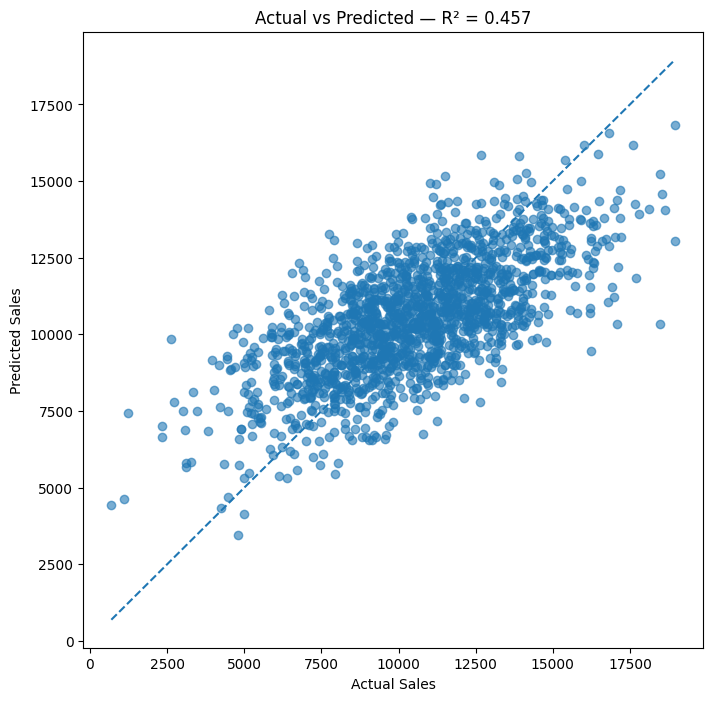

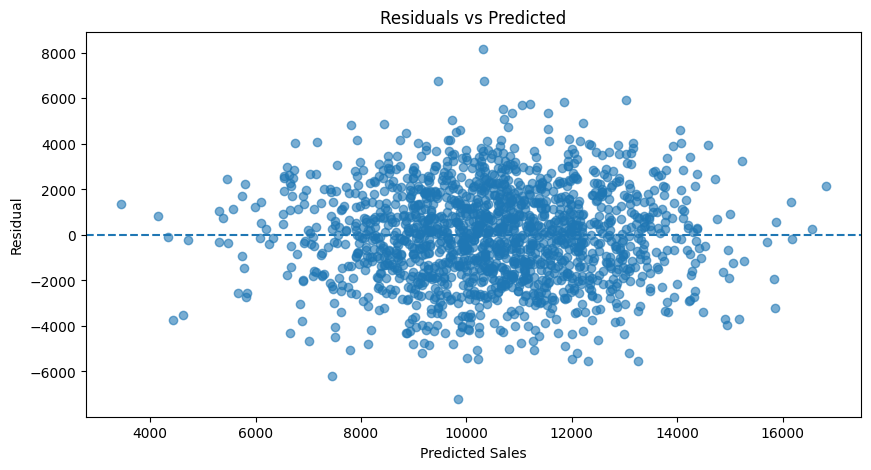

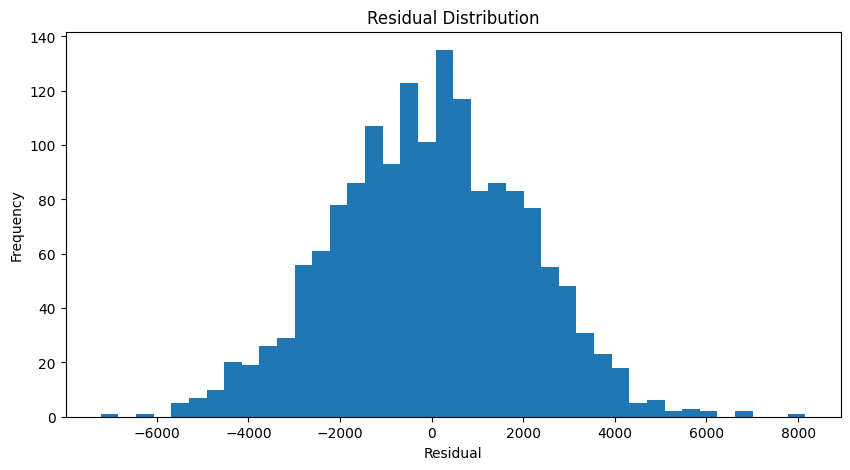

In [ ]:
plt.figure(figsize=(8, 8))
plt.scatter(y_valid, valid_pred, alpha=0.6)

lo = min(y_valid.min(), valid_pred.min())
hi = max(y_valid.max(), valid_pred.max())

plt.plot([lo, hi], [lo, hi], linestyle="--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title(f"Actual vs Predicted — R² = {final_r2:.3f}")
plt.show()

residuals = y_valid.values - valid_pred

plt.figure(figsize=(10, 5))
plt.scatter(valid_pred, residuals, alpha=0.6)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Sales")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted")
plt.show()

plt.figure(figsize=(10, 5))
plt.hist(residuals, bins=40)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual Distribution")
plt.show()


## 13. Feature Importance and Business Interpretation

,Feature,Importance
10,num__log_followers,0.268065
0,num__Followers,0.256993
11,num__log_ad_spend,0.157108
18,num__quality_x_adspend,0.118129
2,num__AdSpend_GBP,0.109910
14,num__engagement_x_adspend,0.026710
13,num__log_engaged_audience,0.013061
15,num__spend_per_follower,0.012610
16,num__followers_per_spend,0.010034
12,num__estimated_engaged_audience,0.007648


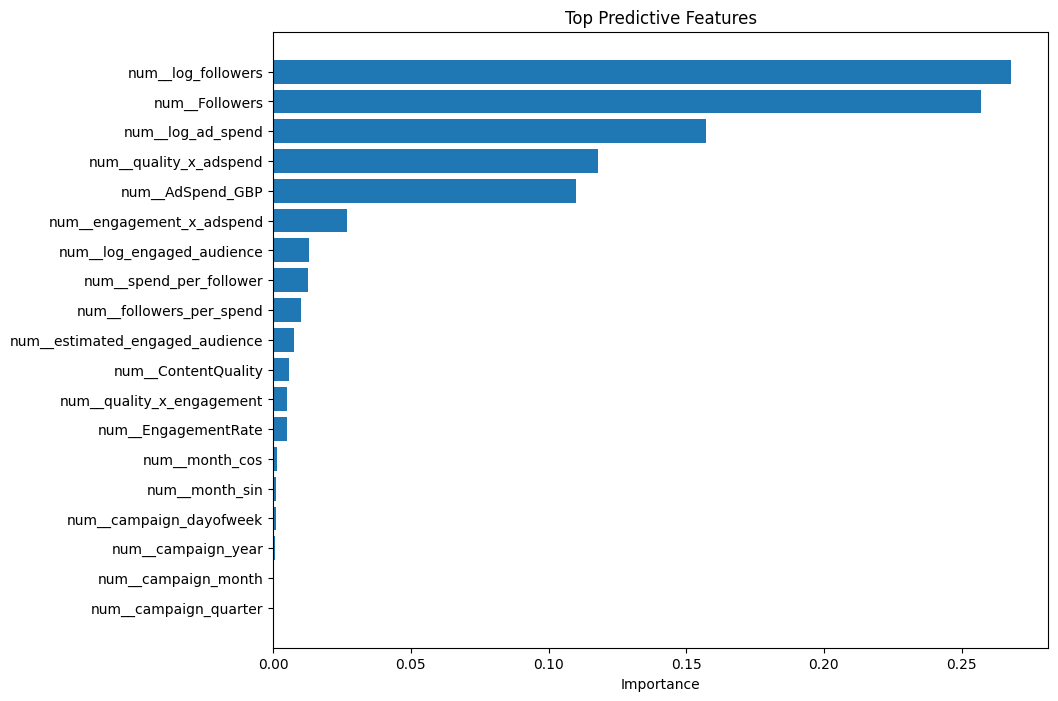

In [ ]:
model_step = final_model_holdout.named_steps["model"]

if hasattr(model_step, "feature_importances_"):
    prep = final_model_holdout.named_steps["preprocessor"]
    feature_names = prep.get_feature_names_out()
    importances = model_step.feature_importances_

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importances
    }).sort_values(
        "Importance",
        ascending=False
    )

    display(importance_df.head(25))

    top = importance_df.head(20).sort_values("Importance")

    plt.figure(figsize=(10, 8))
    plt.barh(
        top["Feature"],
        top["Importance"]
    )
    plt.xlabel("Importance")
    plt.title("Top Predictive Features")
    plt.show()
else:
    importance_df = pd.DataFrame()
    print("Selected model does not expose tree feature_importances_.")


### Business interpretation

- **Followers** represent potential reach, but reach alone does not guarantee sales.
- **Engagement rate** represents audience responsiveness.
- **Ad spend** can increase exposure, but returns may diminish.
- **Content quality** can influence how efficiently attention converts.
- **Followers × engagement rate** estimates the engaged audience.
- Interaction features allow the model to capture combinations of marketing factors.

**Important:** model feature importance represents predictive association, not proof of causation.


## 14. Train on Full Training Data and Predict Test

In [ ]:
# Retrain the selected model using every training observation.
final_model.fit(X, y)

X_test_final = X_test.reindex( columns=X.columns, fill_value=np.nan)

test_pred = np.maximum(final_model.predict(X_test_final),  0)
submission = pd.DataFrame({  TARGET: test_pred})

# Preserve a common identifier if present.
id_cols = [
    c for c in test_raw.columns
    if c.lower() in {"id", "campaign_id", "record_id"}
]

if id_cols:
    submission.insert(0,id_cols[0],test_raw[id_cols[0]].values)

display(submission.head(20))
print("Prediction rows:", len(submission))

assert len(submission) == len(test_raw)
assert submission[TARGET].notna().all()
assert np.isfinite(submission[TARGET]).all()
assert (submission[TARGET] >= 0).all()


,ID,Sales_Units
0,6252,12059.714323
1,4684,8804.236646
2,1731,10347.327995
3,4742,10651.258754
4,4521,11411.988969
5,6340,9139.626951
6,576,11019.589571
7,5202,11524.763260
8,6363,12709.816870
9,439,13116.101619


Prediction rows: 2000


In [ ]:
SUBMISSION_PATH = "/content/submission.csv"
MODEL_PATH = "/content/influencer_sales_model.pkl"
METRICS_PATH = "/content/model_metrics.csv"
METADATA_PATH = "/content/model_metadata.json"

submission.to_csv(
    SUBMISSION_PATH,
    index=False
)

joblib.dump(
    final_model,
    MODEL_PATH
)

metrics = pd.DataFrame([{
    "model": final_model_name,
    "holdout_rmse": final_rmse,
    "holdout_mae": final_mae,
    "holdout_r2": final_r2,
    "best_rf_cv_rmse": -rf_search.best_score_,
    "best_gb_cv_rmse": -gb_search.best_score_
}])

metrics.to_csv(
    METRICS_PATH,
    index=False
)

metadata = {
    "target": TARGET,
    "followers_column": FOLLOWERS_COL,
    "engagement_column": ENGAGEMENT_COL,
    "ad_spend_column": ADSPEND_COL,
    "content_quality_column": CONTENT_COL,
    "timestamp_column": TIMESTAMP_COL,
    "model_name": final_model_name,
    "feature_columns": X.columns.tolist(),
    "holdout_rmse": float(final_rmse),
    "holdout_mae": float(final_mae),
    "holdout_r2": float(final_r2)
}

with open(METADATA_PATH, "w") as f:
    json.dump(metadata, f, indent=2)

print("Saved:")
print(SUBMISSION_PATH)
print(MODEL_PATH)
print(METRICS_PATH)
print(METADATA_PATH)


Saved:
/content/submission.csv
/content/influencer_sales_model.pkl
/content/model_metrics.csv
/content/model_metadata.json


## 15. Reusable Future-Campaign Prediction Pipeline

In [ ]:
def prepare_future_campaign_data(raw_df):
    df = raw_df.copy()

    df.columns = [normalize_column_name(c)
        for c in df.columns    ]

    df = clean_core(df,include_target=False)
    df = add_features(df)
    df = df.drop(columns=DROP_COLUMNS,errors="ignore")
    df = df.reindex(columns=X.columns,fill_value=np.nan)
    return df


def predict_sales(raw_campaign_data):
    prepared = prepare_future_campaign_data(raw_campaign_data)
    predictions = np.maximum(final_model.predict(prepared),0)
    result = raw_campaign_data.copy()
    result["Predicted_Sales"] = predictions
    return result

print("Pipeline ready.")
print("Use: predict_sales(new_campaign_data)")


Pipeline ready.
Use: predict_sales(new_campaign_data)


In [ ]:
# Test the reusable pipeline on the first five test campaigns.
display(predict_sales(test_raw.head(5)))

,Followers,EngagementRate (%),AdSpend (GBP),ContentQuality,ID,Timestamp,Notes,Predicted_Sales
0,179136.0,2.5570425842061986,3975.099954173261,1.803620,6252,2021-10-08,Good,12059.714323
1,68888.0,3.451254744278324,5392.048613170361,2.993966,4684,2021-10-01,Good,8804.236646
2,89520.0,0.7342357926528821,5850.470394900652,4.525990,1731,2021-06-24,NaN,10347.327995
3,100048.0,1.5972073367018218,5792.432498712002,5.051500,4742,2021-11-22,NaN,10651.258754
4,132229.0,1.3874265375395036,5095.269891920688,3.580921,4521,2021-07-19,Review,11411.988969


## 16. Example with Messy Future Data

In [ ]:
example = pd.DataFrame({
    "Followers": ["250K", "1.5M", "750000"],
    "EngagementRate": ["3.2%", "5.5%", "2.8%"],
    "AdSpend": ["£5,000", "£12,500", "3000"],
    "ContentQuality": ["8", "9", "7"],
    "Timestamp": ["2026-08-01", "2026-08-05", "2026-08-10"]
})
display(predict_sales(example))

,Followers,EngagementRate,AdSpend,ContentQuality,Timestamp,Predicted_Sales
0,250K,3.2%,"£5,000",8,2026-08-01,14515.001072
1,1.5M,5.5%,"£12,500",9,2026-08-05,15664.494492
2,750000,2.8%,3000,7,2026-08-10,14424.841508


## 17. Download All Outputs

In [ ]:
from google.colab import files

for path in [SUBMISSION_PATH,MODEL_PATH,METRICS_PATH,METADATA_PATH]:
    files.download(path)

print("Downloads triggered.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloads triggered.


# Final Conclusion

This notebook implements the complete workflow:

1. Messy data ingestion and audit
2. Currency/percentage/unit parsing
3. Business-rule validation
4. Missing-value handling
5. Exploratory analysis
6. Log and interaction features
7. Baseline regression
8. Multiple model comparison
9. Five-fold cross-validation
10. Randomized hyperparameter tuning
11. Holdout RMSE, MAE and R² evaluation
12. Feature importance
13. Full-data final training
14. Test predictions and `submission.csv`
15. Reusable `predict_sales()` pipeline
16. Saved model, metrics and metadata

The pipeline is designed so preprocessing is learned inside the scikit-learn model pipeline, reducing validation/test leakage.
